# Sesiunea 18 · Computer Vision: arhitecturi celebre 🏗️

Data trecută: o imagine = numere, filtre, ResNet18. Azi: **mai multe modele** și **trei sarcini** (clasificare, detecție, segmentare).
Rulezi cu **Shift + Enter**. Unde vezi `___`, completezi tu.

## 0. Pregătire

In [1]:
%pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 23.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 3.9 MB/s eta 0:00:00


In [2]:
# Rulează celula și atât.
import time, io, urllib.request
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
from torchvision import models

def incarca_din_url(url):
    cerere = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    return Image.open(io.BytesIO(urllib.request.urlopen(cerere).read())).convert("RGB")

def arata(*imagini, titluri=None, marime=5):
    fig, axe = plt.subplots(1, len(imagini), figsize=(marime * len(imagini), marime))
    axe = np.atleast_1d(axe)
    for i, (ax, img) in enumerate(zip(axe, imagini)):
        if np.asarray(img).ndim == 2:
            ax.imshow(img, cmap="tab20", vmin=0, vmax=20)   # măști: o culoare pe clasă
        else:
            ax.imshow(img)
        ax.axis("off")
        if titluri: ax.set_title(titluri[i], fontsize=12)
    plt.tight_layout(); plt.show()

def arata_detectii(rezultat):
    arata(rezultat.plot()[:, :, ::-1], marime=8)       # desenează cutiile pe poză

pisica   = incarca_din_url("https://upload.wikimedia.org/wikipedia/commons/3/3a/Cat03.jpg")
autobuz  = incarca_din_url("https://raw.githubusercontent.com/ultralytics/ultralytics/main/ultralytics/assets/bus.jpg")
plaja    = incarca_din_url("https://raw.githubusercontent.com/pjreddie/darknet/master/data/kite.jpg")
print("Gata ✅")

Gata ✅


## 1. Recapitulare: pisica de data trecută
Aceiași pași ca în sesiunea 17: greutăți, rețetă, predicție.

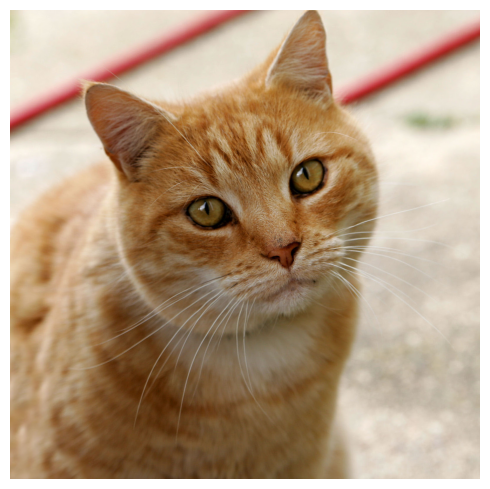

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 125MB/s]


   Egyptian cat              41%
   tiger cat                 39%
   tabby                     15%


In [3]:
def clasifica(poza, nume_model="resnet18", cate=3):
    weights = models.get_model_weights(nume_model).DEFAULT       # greutățile
    model = models.get_model(nume_model, weights=weights).eval() # modelul
    x = weights.transforms()(poza).unsqueeze(0)                  # rețeta → [1, 3, H, W]
    with torch.no_grad():
        probabilitati = model(x).softmax(1)[0]
    top_prob, top_idx = probabilitati.topk(cate)
    for p, i in zip(top_prob, top_idx):
        print(f"   {weights.meta['categories'][i]:25s} {p.item():.0%}")

arata(pisica)
clasifica(pisica)

## 2. Fișa tehnică: mai mare nu înseamnă mai bun
Fiecare model vine cu o „fișă": câți parametri are și cât de precis e pe ImageNet.

alexnet                61.1 mil. parametri   56.5% corect
vgg16                 138.4 mil. parametri   71.6% corect
resnet18               11.7 mil. parametri   69.8% corect
resnet50               25.6 mil. parametri   80.9% corect
mobilenet_v3_large      5.5 mil. parametri   75.3% corect
efficientnet_b0         5.3 mil. parametri   77.7% corect
vit_b_16               86.6 mil. parametri   81.1% corect
convnext_tiny          28.6 mil. parametri   82.5% corect


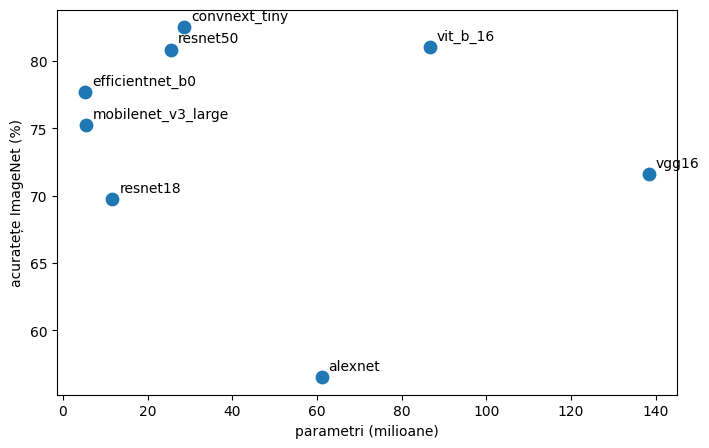

In [4]:
modele = ["alexnet", "vgg16", "resnet18", "resnet50",
          "mobilenet_v3_large", "efficientnet_b0", "vit_b_16", "convnext_tiny"]

nume, parametri, acuratete = [], [], []
for m in modele:
    fisa = models.get_model_weights(m).DEFAULT.meta
    nume.append(m)
    parametri.append(fisa["num_params"] / 1e6)                   # în milioane
    acuratete.append(fisa["_metrics"]["ImageNet-1K"]["acc@1"])
    print(f"{m:20s} {parametri[-1]:6.1f} mil. parametri   {acuratete[-1]:.1f}% corect")

plt.figure(figsize=(8, 5))
plt.scatter(parametri, acuratete, s=80)
for n, x, y in zip(nume, parametri, acuratete):
    plt.annotate(n, (x, y), xytext=(5, 5), textcoords="offset points")
plt.xlabel("parametri (milioane)"); plt.ylabel("acuratețe ImageNet (%)")
plt.show()

**Exercițiul 2.1:** care e mai precis: `vgg16` sau `efficientnet_b0`? De câte ori e mai mare unul decât celălalt?

In [6]:
raspuns = "vgg16"   # 💡 numele modelului, între ghilimele
print("De câte ori e mai mare vgg16:", round(parametri[1] / parametri[5]))

De câte ori e mai mare vgg16: 26


## 3. Același API: schimbi modelul, schimbi un singur cuvânt

In [10]:
for nume_model in ["resnet18", "alexnet", "mobilenet_v3_large", "convnext_tiny"]:     # 💡 un model de la secțiunea 2, între ghilimele
    start = time.time()
    print(nume_model)
    clasifica(pisica, nume_model)
    print(f"   durată: {time.time() - start:.1f} secunde\n")

resnet18
   Egyptian cat              41%
   tiger cat                 39%
   tabby                     15%
   durată: 0.3 secunde

alexnet
   tiger cat                 39%
   tabby                     31%
   Egyptian cat              23%
   durată: 1.5 secunde

mobilenet_v3_large
   Egyptian cat              41%
   tiger cat                 20%
   tabby                     7%
   durată: 0.3 secunde

convnext_tiny
   Egyptian cat              40%
   tiger cat                 34%
   tabby                     4%
   durată: 1.6 secunde



**Exercițiul 3.1:** încearcă `mobilenet_v3_large` și `convnext_tiny`. Care e mai rapid? Sunt de acord pe ce e în poză?

## 4. Trei sarcini, aceeași poză
**Clasificarea** dă o singură etichetă pentru toată poza:

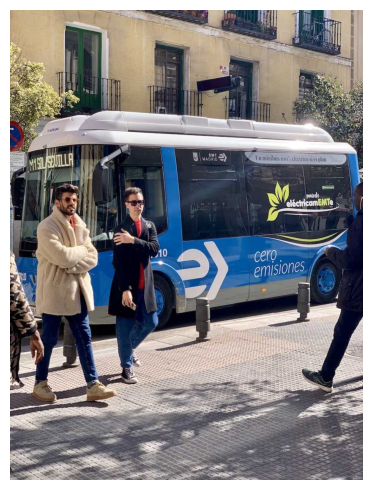

   minibus                   83%
   police van                12%
   recreational vehicle      1%


In [11]:
arata(autobuz)
clasifica(autobuz)

Dar în poză sunt și **oameni**. Ca să aflăm *ce obiecte sunt și unde*, avem nevoie de **detecție**.

## 5. Detecție cu YOLO
Trei rânduri: încărcăm modelul, îi dăm poza, primim cutii.

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


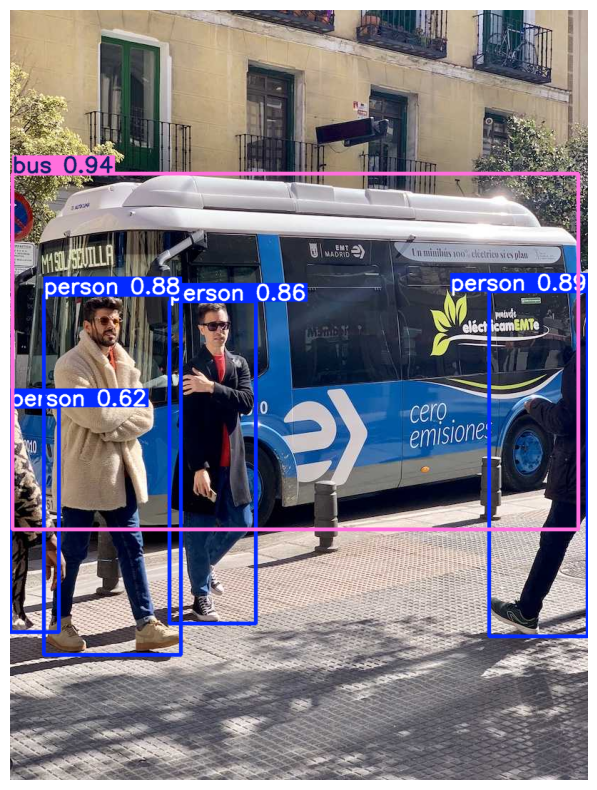

In [12]:
from ultralytics import YOLO

yolo = YOLO("yolo11n.pt")                         # n = nano, cel mai mic și rapid
rezultat = yolo(autobuz, verbose=False)[0]

arata_detectii(rezultat)

Pentru fiecare obiect primim **3 lucruri**: clasa, scorul și cutia `[x1, y1, x2, y2]`.

In [13]:
for cutie in rezultat.boxes:
    clasa = yolo.names[int(cutie.cls)]
    scor = float(cutie.conf)
    colturi = cutie.xyxy[0].int().tolist()
    print(f"{clasa:10s} scor {scor:.2f}   cutie {colturi}")

bus        scor 0.94   cutie [3, 229, 796, 728]
person     scor 0.89   cutie [671, 394, 809, 878]
person     scor 0.88   cutie [47, 399, 239, 904]
person     scor 0.86   cutie [223, 408, 344, 860]
person     scor 0.62   cutie [0, 556, 68, 872]


**Exercițiul 5.1:** schimbă pragul de scor. Câte persoane găsește la 0.2? Dar la 0.9?

Persoane găsite: 0


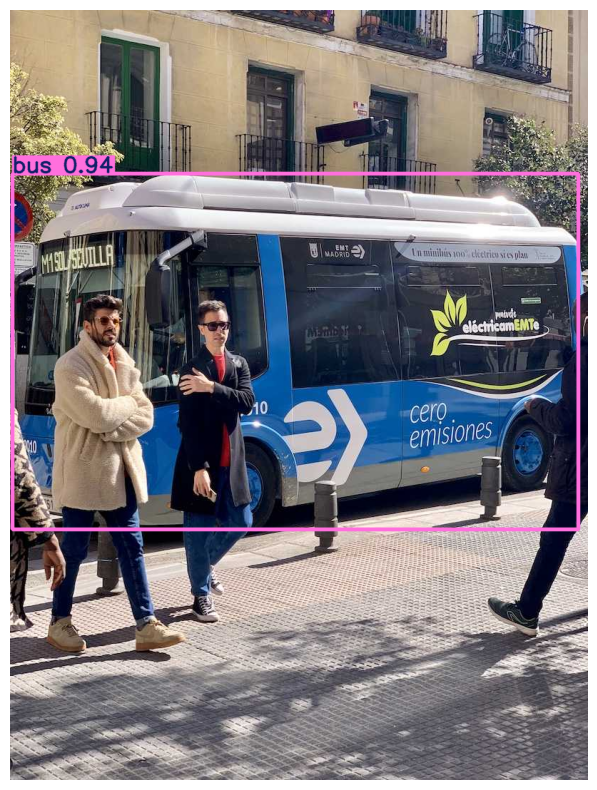

In [15]:
PRAG = 0.9          # 💡 un număr între 0 și 1
rezultat = yolo(autobuz, conf=PRAG, verbose=False)[0]

numar = 0
for cutie in rezultat.boxes:
    if yolo.names[int(cutie.cls)] == "person":
        numar = numar + 1

print("Persoane găsite:", numar)
arata_detectii(rezultat)

## 6. Segmentare: o clasă pentru fiecare pixel

Downloading: "https://download.pytorch.org/models/deeplabv3_mobilenet_v3_large-fc3c493d.pth" to /root/.cache/torch/hub/checkpoints/deeplabv3_mobilenet_v3_large-fc3c493d.pth


100%|██████████| 42.3M/42.3M [00:00<00:00, 66.2MB/s]


input:  (1, 3, 693, 520)
output: (1, 21, 693, 520)
mască:  (693, 520)
clase:  ['__background__', 'aeroplane', 'bicycle', 'bird', 'boat', 'bottle', 'bus', 'car', 'cat', 'chair', 'cow', 'diningtable', 'dog', 'horse', 'motorbike', 'person', 'pottedplant', 'sheep', 'sofa', 'train', 'tvmonitor']


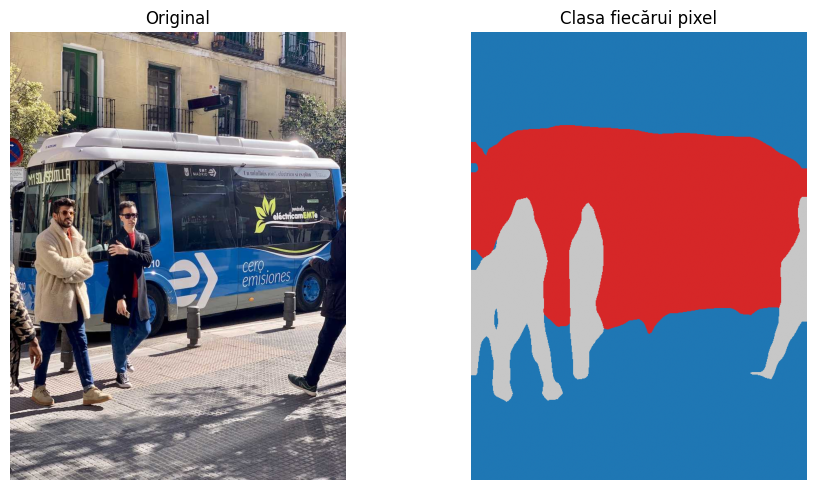

In [16]:
weights_seg = models.segmentation.DeepLabV3_MobileNet_V3_Large_Weights.DEFAULT
segmentator = models.segmentation.deeplabv3_mobilenet_v3_large(weights=weights_seg).eval()
clase_seg = weights_seg.meta["categories"]

x = weights_seg.transforms()(autobuz).unsqueeze(0)
with torch.no_grad():
    scoruri = segmentator(x)["out"]               # [1, 21, H, W]: 21 de scoruri pe pixel
masca = scoruri.argmax(1)[0]                      # [H, W]: clasa câștigătoare pe pixel

print("input: ", tuple(x.shape))
print("output:", tuple(scoruri.shape))
print("mască: ", tuple(masca.shape))
print("clase: ", clase_seg)

arata(autobuz, masca, titluri=["Original", "Clasa fiecărui pixel"])

**Exercițiul 6.1:** alege o clasă din listă și vezi ce pixeli îi aparțin.

In [ ]:
CLASA = ___      # 💡 de exemplu "bus" sau "person", între ghilimele

selectat = (masca == clase_seg.index(CLASA)).numpy()
poza_mica = np.array(autobuz.resize((masca.shape[1], masca.shape[0])))
evidentiat = poza_mica.copy()
evidentiat[selectat] = [255, 80, 0]

arata(poza_mica, evidentiat, titluri=["Original", CLASA])
print(f"{CLASA}: {selectat.mean():.0%} din imagine")

## 7. Use case: salvamarul digital 🏖️
Un salvamar vrea să știe automat **câți oameni sunt la apă** și dacă e **aglomerat**.
Pașii 1 și 2 sunt gata. Pașii 3 și 4 îi scrii tu.

In [ ]:
# Pasul 1: poza.   Pasul 2: detectorul (cu un prag mic, ca să vedem tot).
rezultat_plaja = yolo(plaja, conf=0.1, verbose=False)[0]
arata_detectii(rezultat_plaja)

for cutie in rezultat_plaja.boxes:
    print(f"{yolo.names[int(cutie.cls)]:10s} scor {float(cutie.conf):.2f}")

**Exercițiul 7.1 · Numără:** păstrează doar oamenii, peste un prag ales de tine.

In [ ]:
CLASA = ___     # 💡 ce numărăm? (între ghilimele)
PRAG = ___          # 💡 de la ce scor avem încredere?

numar = 0
for cutie in rezultat_plaja.boxes:
    clasa = yolo.names[int(cutie.cls)]
    scor = float(cutie.conf)
    if clasa == CLASA and scor >= PRAG:
        numar = numar + ___

print("Oameni la apă:", numar)

**Exercițiul 7.2 · Decide:** peste ce limită e aglomerat?

In [ ]:
LIMITA = ___           # 💡 câți oameni sunt prea mulți?

if numar ___ LIMITA:
    print("🚩 Aglomerat! Trimite un salvamar în plus.")
else:
    print("✅ Totul e în regulă.")

Verificare: aceleași cutii pe care le-ai numărat tu.

In [ ]:
id_clasa = list(yolo.names.values()).index(CLASA)
arata_detectii(yolo(plaja, conf=PRAG, classes=[id_clasa], verbose=False)[0])

**Exercițiul 7.3 · Pe datele tale:** schimbă `CLASA` în `"kite"` și numără zmeiele. Apoi încearcă o poză proprie: o parcare (`"car"`), o stradă, un raft.

In [ ]:
from google.colab import files
incarcate = files.upload()
poza_mea = Image.open(list(incarcate.keys())[0]).convert("RGB")

rezultat_meu = yolo(poza_mea, conf=___, verbose=False)[0]
arata_detectii(rezultat_meu)

## 8. Verifică-te: clasificare, detecție sau segmentare?
a) Câte mașini trec pe o stradă?
b) Cât la sută dintr-o frunză e afectată de boală?
c) E pisică sau câine?
d) Unde sunt căștile de protecție pe un șantier?